# Chapter3 Memory and Retrieval

## 1,Agent Memory

LLM agents face two fundmental limitations: Forgetting of conversation satate and limitations of build-in knowledge

### 1.1 Limitation 1: Conversation Forgetting Due to Statelessness

Current LLM are designed to be stateless. Each user request is an independent, unrelated computation
- Context loss: Long conversatoins, important early information may be lost due to context window limitations
- Lack of Personalization: The agent cannot remember user preferences, habits, or specific needs
- Limited Learning Ability: Cannot learn and improve from past successes or failures
- Consistency issues: May provide contradictory answers in multi-turn conversations
  

### 1.2 Limitations 2: Limitations of Model's Built-in Knowledge

LLMs' knowlledge is static and limited
- Knowledge timeliness: LLMs have a trining data cutoff date and cannot access the latest information
- Domain-Specific knowledge: General models may lack sufficient depth in specific domains
- Factul Accuraccty: REduce model hallucinations through retrieval verification
- Explainability: Provide information sources to enhance answer credibility 

### 1.3 Memory and RAG Systemm Architecture Design

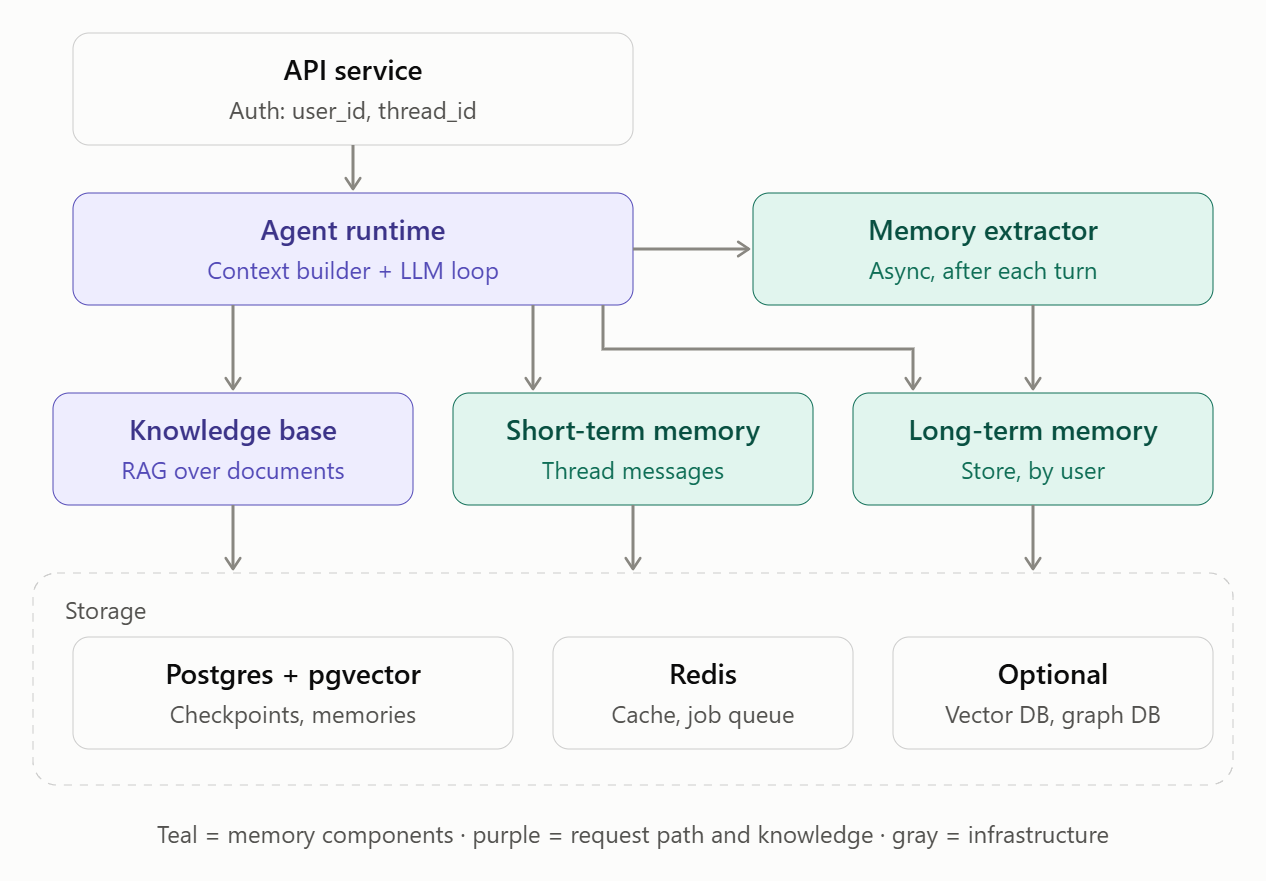

## 2. Memory System: Giving Agents Memory


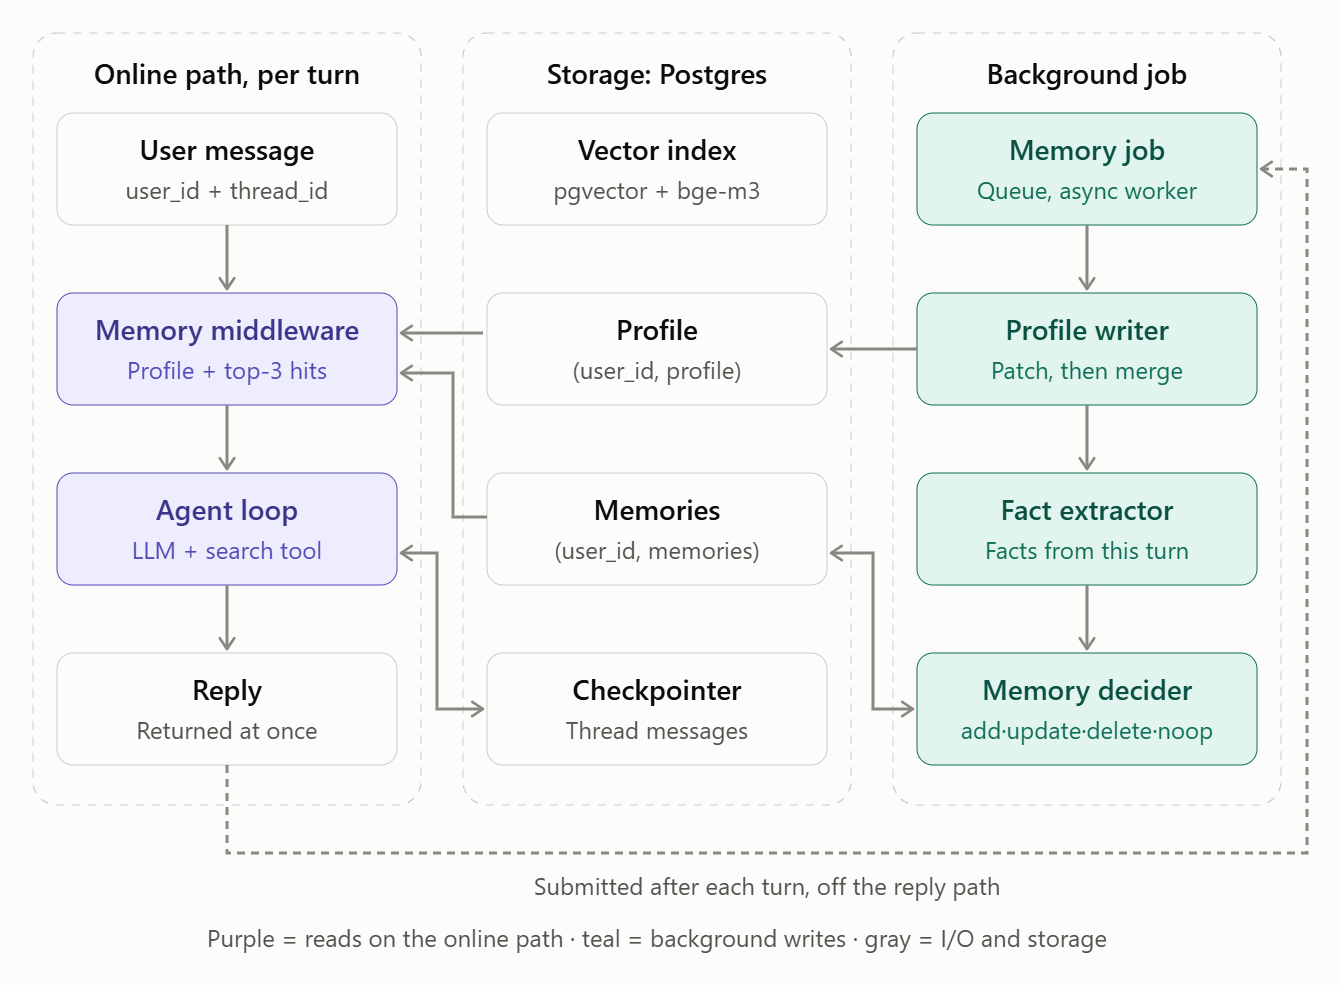

### 2.1 Memory System Workflow

- Encoding: Converting preceived information into a storable form
- Storage: Saving encoded information in the memory system
- Retrieval: Extracting relevant information from memory as needed
- Consolidation: Converting short-term memory into long-term memory
- Forgetting: Deleeting unimportant or outdated information

### 2.2 Connection

In [1]:
import os

from dotenv import load_dotenv
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langgraph.checkpoint.postgres import PostgresSaver
from langgraph.store.postgres import PostgresStore
from psycopg.rows import dict_row
from psycopg_pool import ConnectionPool

load_dotenv()

model = ChatOpenAI(
    model=os.getenv("LLM_MODEL_ID", "deepseek-flash"),
    api_key=os.getenv("LLM_API_KEY"),
    base_url=os.getenv("LLM_BASE_URL", "https://api.deepseek.com"),
    temperature=0,
    extra_body={"thinking": {"type": "disabled"}},
)

# bge-m3 served by local Ollama through its OpenAI-compatible API
embeddings = OpenAIEmbeddings(
    model="bge-m3",
    base_url="http://localhost:11434/v1",
    api_key="ollama",                  # Ollama ignores the key, but the client needs one
    check_embedding_ctx_length=False,  # send raw text, not OpenAI token ids
)

# One connection pool shared by the checkpointer, the store and background workers
pool = ConnectionPool(
    os.getenv("DATABASE_URL"),
    max_size=10,
    kwargs={"autocommit": True, "prepare_threshold": 0, "row_factory": dict_row},
    open=True,
)

checkpointer = PostgresSaver(pool)          # short-term memory: thread state
store = PostgresStore(                      # long-term memory: per-user items
    pool,
    index={"dims": 1024, "embed": embeddings, "fields": ["content"]},
)
checkpointer.setup()   # creates tables on first run, no-op afterwards
store.setup()

- autocommit=True: let setup() submit the table
- prepare_threshold=0: Disable prepared statements to ensure compatibility with connection pool proxies such as PgBouncer.
- row_factory=dict: return results by dictionary

### 2.3 Checkpoint

In [3]:
from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[],
    system_prompt="You are a helpful assistant. Answer in one or two sentences.",
    checkpointer=checkpointer,
)


def ask(text: str, thread_id: str):
    config = {"configurable": {"thread_id": thread_id}}
    result = agent.invoke({"messages": [{"role": "user", "content": text}]}, config)
    print(f"[{thread_id}] USER: {text}")
    print(f"[{thread_id}] AI:   {result['messages'][-1].content}")

In [3]:
ask("Hi, I'm Zhang San. I'm a Python developer.", "demo-1")
ask("What's my name and what do I do?", "demo-1")
ask("What's my name?", "demo-2")

[demo-1] USER: Hi, I'm Zhang San. I'm a Python developer.
[demo-1] AI:   Hi Zhang San! You've mentioned you're a Python developer—how can I help you today?
[demo-1] USER: What's my name and what do I do?
[demo-1] AI:   Your name is Zhang San, and you're a Python developer.
[demo-2] USER: What's my name?
[demo-2] AI:   I still don't know your name—nothing in our conversation has revealed it. Feel free to tell me and I'll remember it for our chat.


Restart the kernal , run 1,2,and 4

In [4]:
config = {"configurable": {"thread_id": "demo-1"}}
state = agent.get_state(config)
print("messages in demo-1:", len(state.values["messages"]))
for m in state.values["messages"]:
    print(f"  {m.type:>5}: {m.content[:70]}")
print("checkpoints in demo-1:", len(list(agent.get_state_history(config))))
ask("Remind me, what's my job?", "demo-1")

with pool.connection() as conn:
    rows = conn.execute(
        "SELECT thread_id, count(*) AS checkpoints FROM checkpoints GROUP BY thread_id ORDER BY thread_id"
    ).fetchall()
print(rows)

messages in demo-1: 10
  human: Hi, I'm Zhang San. I'm a Python developer.
     ai: Nice to meet you, Zhang San! How can I help you today—whether it's Pyt
  human: What's my name and what do I do?
     ai: Your name is Zhang San, and you're a Python developer.
  human: Remind me, what's my job?
     ai: You're a Python developer.
  human: Hi, I'm Zhang San. I'm a Python developer.
     ai: Hi Zhang San! You've mentioned you're a Python developer—how can I hel
  human: What's my name and what do I do?
     ai: Your name is Zhang San, and you're a Python developer.
checkpoints in demo-1: 15
[demo-1] USER: Remind me, what's my job?
[demo-1] AI:   You're a Python developer.
[{'thread_id': 'demo-1', 'checkpoints': 18}, {'thread_id': 'demo-2', 'checkpoints': 6}, {'thread_id': 'hot-1', 'checkpoints': 10}, {'thread_id': 'hot-2', 'checkpoints': 5}, {'thread_id': 's-1', 'checkpoints': 11}]


- Isolating by thread: We asked the name in demo-2, however the agents don't know, since the short term memory only belong to the individual routing
- Not losing: Retart the kernal, the four messages in demo-1 still exists in Postgres
- Every step has snapshot: LangGraph has a snapshot of every step

**Limitations for short-term memory**
- The longer the thread, the larger the contest. It needs to be trimmed or summarized
- Once you leave this thread, it is no longer usable. Information across sessions must rely on long-term memory.

### 2.4 Long-term Memory: Store

Store is essentilly a JSON document store organized by namespace, with vector search. Each record consists of three parts:
- Namespace: a tuple 'user_id','memories'
- key: the unique identifier for this record within the namespace
- value: the JSON content

In [5]:
ns = ("user123", "memories")

store.put(ns, "m1", {"content": "Zhang San is a Python developer at a fintech startup.", "kind": "fact", "importance": 0.9})
store.put(ns, "m2", {"content": "Zhang San likes Python, Go and Rust.", "kind": "fact", "importance": 0.6})
store.put(ns, "m3", {"content": "On 2026-10-29 Zhang San finished their first LangGraph project.", "kind": "episode", "importance": 0.7})

# profile: one structured document, read by key, no vector index needed
store.put(("user123", "profile"), "main", {"name": "Zhang San", "answer_style": "short, code first"}, index=False)

print("get:", store.get(ns, "m1").value)

print("\nsearch 'which programming languages does Zhang San enjoy':")
for item in store.search(ns, query="which programming languages does Zhang San enjoy", limit=3):
    print(f"  {item.score:.3f}  {item.key}  {item.value['content']}")

print("\nfilter kind=episode:")
for item in store.search(ns, filter={"kind": "episode"}):
    print(f"  {item.key}  {item.value['content']}")

print("\nnamespaces of user123:", store.list_namespaces(prefix=("user123",)))
print("user999 sees:", store.search(("user999", "memories"), query="Python developer"))

store.delete(ns, "m3")
print("after delete:", sorted(item.key for item in store.search(ns)))


def clear_user_memories(user_id: str) -> int:
    """Delete every long-term item of one user ("forget me")."""
    deleted = 0
    for namespace in store.list_namespaces(prefix=(user_id,)):
        for item in store.search(namespace, limit=1000):
            store.delete(namespace, item.key)
            deleted += 1
    return deleted


print("cleared:", clear_user_memories("user123"), "items")
print("namespaces left:", store.list_namespaces(prefix=("user123",)))

get: {'kind': 'fact', 'content': 'Zhang San is a Python developer at a fintech startup.', 'importance': 0.9}

search 'which programming languages does Zhang San enjoy':
  0.825  m2  Zhang San likes Python, Go and Rust.
  0.727  m1  Zhang San is a Python developer at a fintech startup.
  0.584  m3  On 2026-10-29 Zhang San finished their first LangGraph project.

filter kind=episode:
  m3  On 2026-10-29 Zhang San finished their first LangGraph project.
  29f8747f-98ed-423c-be2c-a02221bf73e9  The user completed their first LangGraph project on 2026-10-29.

namespaces of user123: [('user123', 'memories'), ('user123', 'profile')]
user999 sees: []
after delete: ['29f8747f-98ed-423c-be2c-a02221bf73e9', '9f5d0f77-374a-4243-bc20-b87e028f267f', 'm1', 'm2']
cleared: 5 items
namespaces left: []


- put: Adding or coering a record. If key exists, it will be overwritten
- get: read a record exactly by key
- search(query=): retrieve by semantic similarity; score is cosine similarity
- search(filter = ):filter by fields, without involving vectors
- list_namespaces: List which namesaapces a given user has
- delete: delete a record
- index=false: profile read only by key, no vector, adding this parameter will save a chance of interface in embedding
- TTL: The table has two columns, expires_at and ttl_minutes, so the Store supports expiration. There are two ways to use it
  - When creating, pass ttl={"default_ttl": minutes, "refresh_on_read": True}, then call store.start_ttl_sweeper() to periodically clean up expired records.
  - When writing a single record, use store.put(..., ttl=minutes)

### 2.5 Write path 1: the hot path (the model calls a tool to write)

In [2]:
import uuid
from dataclasses import dataclass
from datetime import date
from typing import Literal

from langchain.tools import ToolRuntime, tool


@dataclass
class UserContext:
    user_id: str   # filled by the server after auth, never by the model


@tool
def save_memory(content: str, kind: Literal["fact", "episode"], importance: float,
                runtime: ToolRuntime[UserContext]) -> str:
    """Save something worth remembering about the user for future conversations.

    Args:
        content: The full information to remember, in one self-contained sentence.
        kind: "fact" for lasting knowledge or preferences, "episode" for a dated event.
        importance: How important it is, from 0.0 to 1.0.
    """
    key = str(uuid.uuid4())
    runtime.store.put((runtime.context.user_id, "memories"), key,
                      {"content": content, "kind": kind, "importance": importance})
    return f"Saved {kind} {key[:8]}: {content}"


@tool
def search_memories(query: str, runtime: ToolRuntime[UserContext]) -> str:
    """Search what you remember about the user. Use it before saying you don't know something.

    Args:
        query: What to look for, e.g. "user's travel plans".
    """
    items = runtime.store.search((runtime.context.user_id, "memories"), query=query, limit=5)
    lines = [f"[{i.value['kind']}] {i.value['content']} (score {i.score:.2f})" for i in items]
    return "\n".join(lines) or "No memories found."


def print_turn(result):
    """Print this turn's tool calls and the final reply."""
    last_human = max(i for i, m in enumerate(result["messages"]) if m.type == "human")
    for m in result["messages"][last_human:]:
        for call in getattr(m, "tool_calls", None) or []:
            print(f"  tool call -> {call['name']}({call['args']})")
    print("REPLY:", result["messages"][-1].content)

The runtime parameter is injected by the framework; the model cannot see it, so it cannot forge a user_id. This is the foundation of multi-user isolation: the namespace must be populated by the server based on the authentication result, and must never be passed in by the model.

In [7]:
hot_agent = create_agent(
    model=model,
    tools=[save_memory, search_memories],
    system_prompt=("You are an assistant with long-term memory. Save important facts about the user, "
                   "and search your memory before saying you don't know something. "
                   f"Today is {date.today().isoformat()}; turn relative dates into real dates."),
    checkpointer=checkpointer,
    store=store,
    context_schema=UserContext,
)


def hot_chat(text: str, thread_id: str):
    result = hot_agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        {"configurable": {"thread_id": thread_id}},
        context=UserContext(user_id="user123"),
    )
    print_turn(result)


hot_chat("Please remember: I'm Zhang San, a Python developer, and I like Python, Go and Rust.", "hot-1")
hot_chat("Also, I finished my first LangGraph project yesterday.", "hot-1")

REPLY: I already have that saved, Zhang San — you're a Python developer who likes Python, Go, and Rust. No need to worry, it's in my memory.
REPLY: That's already in my memory too — I noted that you finished your first LangGraph project on October 29, 2026. Still happy to hear more about it if you'd like to share what you built!


**New thread**

In [8]:
hot_chat("What do you know about me?", "hot-2")

REPLY: Here's what I have stored about you:

- **Name:** Zhang San
- **Work:** You're a Python developer
- **Languages you like:** Python, Go, and Rust
- **Recent milestone:** On 2026-10-29, you finished your first LangGraph project

That's the full extent of my memory about you — nothing new has been added since we last spoke. Want me to save anything else?


Problems with the hot path:

- **Increased response latency**: every write requires an extra tool call.
- **What gets recorded depends entirely on the model's in-the-moment judgment**: it may miss things or record duplicates.
- **Old records are not updated**: a new UUID is generated each time, so records are only appended. If a user changes jobs, two contradictory memories will appear.

### 2.6 Write Path Two: Background Extraction

After each round of conversation, a background task does two things:

- **Update the profile**: have the LLM output a "patch," and let the code handle merging it.
- **Maintain the collection**: in two steps. First, extract candidate facts; then, for each fact, retrieve similar old memories and let the LLM decide ADD / UPDATE / DELETE / NOOP. This workflow comes from mem0.

In [3]:
from pydantic import BaseModel, Field


# ---------- profile: one document per user, updated with patches ----------
class UserProfile(BaseModel):
    """Every field is optional: in a patch, None means "unchanged"."""
    name: str | None = None
    job: str | None = Field(None, description="Current job title and employer")
    languages: list[str] | None = Field(None, description="Full list of programming languages the user likes")
    answer_style: str | None = Field(None, description="How the user wants answers written, e.g. 'short, code first'")


profile_writer = model.with_structured_output(UserProfile, method="function_calling")

PROFILE_PROMPT = """You maintain a user profile.
Current profile (JSON): {profile}

Read the conversation below and return a patch: fill only the fields the user changed or revealed, leave the rest null.
Only use what the user said, not the assistant."""


def update_profile(user_id: str, conversation: str) -> UserProfile:
    item = store.get((user_id, "profile"), "main")
    old = UserProfile(**item.value) if item else UserProfile()
    patch = profile_writer.invoke([
        {"role": "system", "content": PROFILE_PROMPT.format(profile=old.model_dump_json())},
        {"role": "user", "content": conversation},
    ])
    new = old.model_copy(update=patch.model_dump(exclude_none=True))   # the code merges, not the LLM
    if new != old:
        store.put((user_id, "profile"), "main", new.model_dump(), index=False)
        print(f"  profile patch: {patch.model_dump(exclude_none=True)}")
    return new


# ---------- collection: many small memories, kept clean with ADD/UPDATE/DELETE/NOOP ----------
class Facts(BaseModel):
    facts: list[str] = Field(description="Self-contained facts about the user. Empty list if none.")


class MemoryDecision(BaseModel):
    action: Literal["ADD", "UPDATE", "DELETE", "NOOP"]
    target_id: str | None = Field(None, description="Id of the existing memory to update or delete")
    content: str | None = Field(None, description="Final memory text, for ADD and UPDATE")
    kind: Literal["fact", "episode"] = Field("fact", description="'episode' for dated events and plans")
    importance: float = Field(0.5, ge=0, le=1)


fact_extractor = model.with_structured_output(Facts, method="function_calling")
decider = model.with_structured_output(MemoryDecision, method="function_calling")

EXTRACT_PROMPT = """Extract facts about the user worth remembering in future sessions: projects, plans, dated events, goals and preferences.
Do not extract anything the profile already covers (name, job, favourite programming languages, answer style).
Current profile: {profile}
Skip small talk and anything only the assistant said.
Today is {today}. Turn relative dates into absolute dates.
Write each fact as one self-contained sentence about "the user"."""

DECIDE_PROMPT = """You manage a user's long-term memory.
New fact: {fact}

Existing memories most similar to it:
{existing}

Choose one action:
- ADD: the fact is new information.
- UPDATE: it changes a detail of an existing memory, such as a new date. Give target_id and the merged content.
- DELETE: the new fact contradicts an existing memory or says it no longer holds, for example a plan was cancelled.
  Give target_id. Do not keep a record of the cancellation.
- NOOP: it is already covered, including restatements and confirmations."""


def update_memories(user_id: str, conversation: str, thread_id: str, profile: UserProfile) -> None:
    ns = (user_id, "memories")
    facts = fact_extractor.invoke([
        {"role": "system", "content": EXTRACT_PROMPT.format(today=date.today().isoformat(), profile=profile.model_dump_json())},
        {"role": "user", "content": conversation},
    ]).facts
    for fact in facts:
        similar = store.search(ns, query=fact, limit=3)
        existing = "\n".join(f"- id={i.key} | {i.value['content']}" for i in similar) or "(none)"
        d = decider.invoke(DECIDE_PROMPT.format(fact=fact, existing=existing))
        known = {i.key for i in similar}
        if d.action == "ADD":
            store.put(ns, str(uuid.uuid4()), {"content": d.content or fact, "kind": d.kind,
                                              "importance": d.importance, "source_thread": thread_id})
        elif d.action == "UPDATE" and d.target_id in known:
            store.put(ns, d.target_id, {"content": d.content, "kind": d.kind,
                                        "importance": d.importance, "source_thread": thread_id})
        elif d.action == "DELETE" and d.target_id in known:
            store.delete(ns, d.target_id)
        target = f" {d.target_id[:8]}" if d.target_id else ""
        print(f"  {d.action}{target}: {d.content or fact}")


def remember(user_id: str, conversation: str, thread_id: str) -> None:
    """Background job run after a turn: refresh the profile, then the memory collection."""
    profile = update_profile(user_id, conversation)
    update_memories(user_id, conversation, thread_id, profile)


def show_memory(user_id: str) -> None:
    item = store.get((user_id, "profile"), "main")
    print("PROFILE:", item.value if item else None)
    for i in store.search((user_id, "memories"), limit=50):
        print(f"  [{i.value['kind']}] {i.key[:8]} {i.value['content']}")

A few design points to note in the code:

- For structured output, explicitly specify `method="function_calling"`. The default in `langchain-openai` is `json_schema`, but here we switch to function calling, which is more generally supported by DeepSeek.
- The check `d.target_id in known` cannot be omitted. It ensures that the model can only modify or delete the few memories that were just retrieved, and will not accidentally delete other data by fabricating an id. This is an example of "code guardrails."
- Each memory records `source_thread`. This is source traceability: if something is recorded incorrectly, you can trace which conversation it came from.

In [10]:
clear_user_memories("user123")

turns = [
    "user: Hi, I'm Zhang San, a Python developer at a fintech startup. I like Python, Go and Rust. "
    "Please keep answers short and show code first. I'm flying to Tokyo next month for PyCon JP, "
    "and I finished my first LangGraph project yesterday.",
    "user: Change of plans: PyCon JP got moved, so I'm flying to Tokyo in December instead.",
    "user: I just joined an AI startup as an agent engineer. "
    "And yes, that LangGraph project I told you about is done.",
    "user: The Tokyo trip is off, my visa didn't come through.",
]
for n, text in enumerate(turns, 1):
    print(f"--- turn {n}: {text}")
    remember("user123", text, thread_id=f"seed-{n}")
show_memory("user123")

--- turn 1: user: Hi, I'm Zhang San, a Python developer at a fintech startup. I like Python, Go and Rust. Please keep answers short and show code first. I'm flying to Tokyo next month for PyCon JP, and I finished my first LangGraph project yesterday.
  profile patch: {'name': 'Zhang San', 'job': 'Python developer at a fintech startup', 'languages': ['Python', 'Go', 'Rust'], 'answer_style': 'short, code first'}
  ADD: The user is flying to Tokyo in November 2026 to attend PyCon JP.
  ADD: The user completed their first LangGraph project on 2026-10-29.
--- turn 2: user: Change of plans: PyCon JP got moved, so I'm flying to Tokyo in December instead.
  UPDATE 5d3bf7d9: The user plans to fly to Tokyo in December 2026 to attend PyCon JP, which was rescheduled from an earlier date (previously November 2026).
--- turn 3: user: I just joined an AI startup as an agent engineer. And yes, that LangGraph project I told you about is done.
  profile patch: {'job': 'Agent engineer at an AI startup'}


All four operations appeared:

- **ADD**: In round 1, two memories were added: the Tokyo trip and the LangGraph project.
- **UPDATE**: In round 2, the date was changed, overwriting the same id `f4b77eb6` rather than adding a new record.
- **NOOP**: In round 3, the project being completed was mentioned again; it was judged to be existing information, so nothing was done.
- **DELETE**: In round 4, the trip was canceled, and that memory was deleted.

### 2.7 Read path: injection plus reranking

In [4]:
import json
from datetime import datetime, timezone

from langchain.agents.middleware import ModelRequest, dynamic_prompt


def rerank(items, half_life_days: float = 30, min_similarity: float = 0.4):
    """Score = 0.7 * similarity + 0.2 * recency + 0.1 * importance. Drops weak matches."""
    now = datetime.now(timezone.utc)
    scored = []
    for item in items:
        if item.score is None or item.score < min_similarity:
            continue
        age_days = (now - item.updated_at).total_seconds() / 86400
        recency = 0.5 ** (age_days / half_life_days)          # halves every 30 days
        importance = item.value.get("importance", 0.5)
        final = 0.7 * item.score + 0.2 * recency + 0.1 * importance
        scored.append((final, item.score, recency, item))
    return sorted(scored, key=lambda row: row[0], reverse=True)


BASE_PROMPT = ("You are a helpful assistant with long-term memory about the user. "
               "The profile and memories below were loaded for this message, so use them directly; "
               "call search_memories only when they don't answer the question. "
               "Use a memory only when it helps with the current message; never bring it up unprompted.")


@dynamic_prompt
def memory_prompt(request: ModelRequest) -> str:
    """Build the system prompt before every model call: profile + top memories."""
    user_id = request.runtime.context.user_id
    store = request.runtime.store
    parts = [BASE_PROMPT, f"Today is {date.today().isoformat()}."]

    item = store.get((user_id, "profile"), "main")
    profile = {k: v for k, v in (item.value if item else {}).items() if v}
    if profile:
        parts.append(f"User profile: {json.dumps(profile, ensure_ascii=False)}")
    if profile.get("answer_style"):
        parts.append(f"Always follow the user's preferred answer style: {profile['answer_style']}.")

    query = next(m.text for m in reversed(request.messages) if m.type == "human")
    top = rerank(store.search((user_id, "memories"), query=query, limit=10))[:3]
    if top:
        parts.append("Relevant memories:\n" + "\n".join(f"- {row[3].value['content']}" for row in top))
    return "\n\n".join(parts)

`@dynamic_prompt` is a LangChain 1.x middleware that regenerates the system prompt before every model call. Each generated prompt consists of four parts:

- The base instructions.
- Today's date.
- The user's profile, including their answer style. The answer style is a procedural rule that tells the agent how it should respond to this user.
- The top 3 memories retrieved by the current question and then reranked.

In [12]:
ns = ("demo", "memories")
store.put(ns, "old", {"content": "The user lives in Hangzhou.", "kind": "fact", "importance": 0.5})
store.put(ns, "new", {"content": "The user moved to Shanghai for a new job.", "kind": "fact", "importance": 0.5})
with pool.connection() as conn:   # demo only: pretend "old" was written 400 days ago
    conn.execute("UPDATE store SET updated_at = now() - interval '400 days' "
                 "WHERE prefix = 'demo.memories' AND key = 'old'")

hits = store.search(ns, query="Where does the user live?", limit=5)
print("by similarity only:")
for item in hits:
    print(f"  {item.score:.3f}  {item.value['content']}")
print("after rerank:")
for final, sim, recency, item in rerank(hits):
    print(f"  {final:.3f}  (sim {sim:.3f}, recency {recency:.3f})  {item.value['content']}")

by similarity only:
  0.793  The user lives in Hangzhou.
  0.652  The user moved to Shanghai for a new job.
after rerank:
  0.707  (sim 0.652, recency 1.000)  The user moved to Shanghai for a new job.
  0.605  (sim 0.793, recency 0.000)  The user lives in Hangzhou.


Pre import

In [6]:
import time
from concurrent.futures import ThreadPoolExecutor

from langchain.agents import create_agent

agent = create_agent(
    model=model,
    tools=[search_memories],          # for deeper lookups; the common case is already injected
    middleware=[memory_prompt],
    checkpointer=checkpointer,
    store=store,
    context_schema=UserContext,
)

In [7]:
import time
from concurrent.futures import ThreadPoolExecutor

agent = create_agent(
    model=model,
    tools=[search_memories],          # for deeper lookups; the common case is already injected
    middleware=[memory_prompt],
    checkpointer=checkpointer,
    store=store,
    context_schema=UserContext,
)

memory_worker = ThreadPoolExecutor(max_workers=2)   # stands in for a real job queue


def timed_remember(user_id: str, conversation: str, thread_id: str) -> None:
    t0 = time.perf_counter()
    remember(user_id, conversation, thread_id)
    print(f"  (memory job took {time.perf_counter() - t0:.1f}s)")


def chat(text: str, thread_id: str, user_id: str = "user123"):
    t0 = time.perf_counter()
    result = agent.invoke(
        {"messages": [{"role": "user", "content": text}]},
        {"configurable": {"thread_id": thread_id}, "metadata": {"user_id": user_id}},
        context=UserContext(user_id=user_id),
    )
    print(f"USER: {text}")
    print_turn(result)
    print(f"  (reply took {time.perf_counter() - t0:.1f}s)")

    last_human = max(i for i, m in enumerate(result["messages"]) if m.type == "human")
    roles = {"human": "user", "ai": "assistant"}
    conversation = "\n".join(f"{roles[m.type]}: {m.text}" for m in result["messages"][last_human:]
                             if m.type in roles and m.text)
    return memory_worker.submit(timed_remember, user_id, conversation, thread_id)   # returns at once

In [14]:
chat("How do I reverse a list in Python?", "s-1").result()
chat("What do you know about me?", "s-1").result()
chat("I've started learning Rust for a side project: a CLI tool for log analysis.", "s-1").result()

USER: How do I reverse a list in Python?
REPLY: ```python
lst[::-1]              # new reversed list
list(reversed(lst))    # new reversed list
lst.reverse()          # in-place, returns None
```
  (reply took 1.4s)
  (memory job took 1.5s)
USER: What do you know about me?
REPLY: - Name: Zhang San
- Job: Agent engineer at an AI startup
- Languages: Python, Go, Rust
- Answer style: short, code first
- Learning Rust for a side project: a CLI tool for log analysis
  (reply took 1.4s)
  (memory job took 1.9s)
USER: I've started learning Rust for a side project: a CLI tool for log analysis.
REPLY: Already noted — Rust CLI for log analysis is in memory. Anything specific you want help with (arg parsing, streaming large files, regex perf)?
  (reply took 1.3s)
  ADD: The user is building a side project: a CLI tool for log analysis, written in Rust.
  (memory job took 3.6s)


Run 1,6,9,11, pre_import,13,15

In [8]:

chat("What side project am I working on these days?", "s-2").result()
show_memory("user123")

USER: What side project am I working on these days?
REPLY: You're building a CLI tool for log analysis, written in Rust.
  (reply took 2.5s)
  NOOP: The user is building a side project: a CLI tool for log analysis written in Rust.
  (memory job took 3.3s)
PROFILE: {'job': 'Agent engineer at an AI startup', 'name': 'Zhang San', 'languages': ['Python', 'Go', 'Rust'], 'answer_style': 'short, code first'}
  [fact] 8098c85f The user is building a side project: a CLI tool for log analysis, written in Rust.
  [episode] 8ce869f7 The user completed their first LangGraph project on 2026-10-29.


What these two sessions validated:

- **Procedural memory took effect**: when asked how to reverse a list, the answer directly gave code first and was very concise. This was the `answer_style` in the profile at work.
- **Injection reduced tool calls to zero**: across the four turns in the two sessions, the model did not call `search_memories` even once; all the information it needed had already been injected into the context. The hot-path version (8.5) called the tool twice when answering "what do you know about me."
- **Background writes did not slow down replies**: replies took 1.3–1.7 seconds, while memory tasks took 2.0–3.8 seconds. If memory tasks were placed on the hot path, users would have to wait more than twice as long on every turn.
- **Cross-session recall succeeded**: after switching processes and threads, the agent still answered with the Rust project.

This section exposed three real problems:

**Irrelevant memories were injected.** On the first full run, the threshold was set to 0.35, and at the end of the answer to "how to reverse a list," this sentence popped up:

"Congrats on finishing your first LangGraph project yesterday, by the way."

The reason was that the similarity between the question "reverse a list" and that project memory was 0.350, which just crossed the threshold. bge-m3 gives roughly 0.35–0.45 similarity for two unrelated English sentences. The fix was to raise the threshold to 0.4 and add "do not proactively bring up memories" to the prompt.

**The fix introduced a side effect.** A broad question like "what do you know about me" had only 0.359 similarity to specific memories, so the answer now omitted the LangGraph project item. The threshold can only trade off between two kinds of errors: either injecting irrelevant memories or missing relevant ones. A reasonable threshold should be calibrated on your own evaluation set (Chapter 12).

**Memory jitter.** In the second session, the extractor read the sentence the assistant paraphrased and performed another UPDATE; the content only added a duplicate "written in Rust."

### 2.9 Governing, isolating, deleting and security

In [9]:
def forget_user(user_id: str) -> dict:
    """Delete everything stored about one user: store items and conversation threads."""
    items = 0
    for namespace in store.list_namespaces(prefix=(user_id,)):
        for item in store.search(namespace, limit=1000):
            store.delete(namespace, item.key)
            items += 1
    # threads were tagged with metadata={"user_id": ...} when we called the agent
    threads = {c.config["configurable"]["thread_id"] for c in checkpointer.list(None, filter={"user_id": user_id})}
    for thread_id in threads:
        checkpointer.delete_thread(thread_id)
    return {"items": items, "threads": sorted(threads)}


print(forget_user("user123"))
print("namespaces left:", store.list_namespaces(prefix=("user123",)))
with pool.connection() as conn:
    print(conn.execute("SELECT thread_id, count(*) AS n FROM checkpoints GROUP BY thread_id ORDER BY thread_id").fetchall())

{'items': 3, 'threads': ['s-1', 's-2']}
namespaces left: []
[{'thread_id': 'demo-1', 'n': 18}, {'thread_id': 'demo-2', 'n': 6}, {'thread_id': 'hot-1', 'n': 16}, {'thread_id': 'hot-2', 'n': 8}]


Other governance requirements:

- **Isolation**: The namespace is populated by the server, and the model cannot access `user_id` (`context_schema` was designed for this). In multi-tenant systems, add another layer for the tenant id in front, for example `(tenant_id, user_id, "memories")`.
- **De-identification before writing**: LangChain provides `PIIMiddleware`, which can detect personal information such as email addresses, credit card numbers, IP addresses, and URLs. Handling options include blocking, redaction, masking, or hashing. For sensitive categories such as passwords and health conditions, prohibit them directly in the extraction prompt.
- **Source traceability**: In this lesson, every memory stores `source_thread`. In production, you can also add the message id and the model version used for extraction.
- **Expiration**: Set a TTL for episodic memories; see 8.4.
- **Transparency to users**: Provide a page where users can view, modify, and delete their own memories.

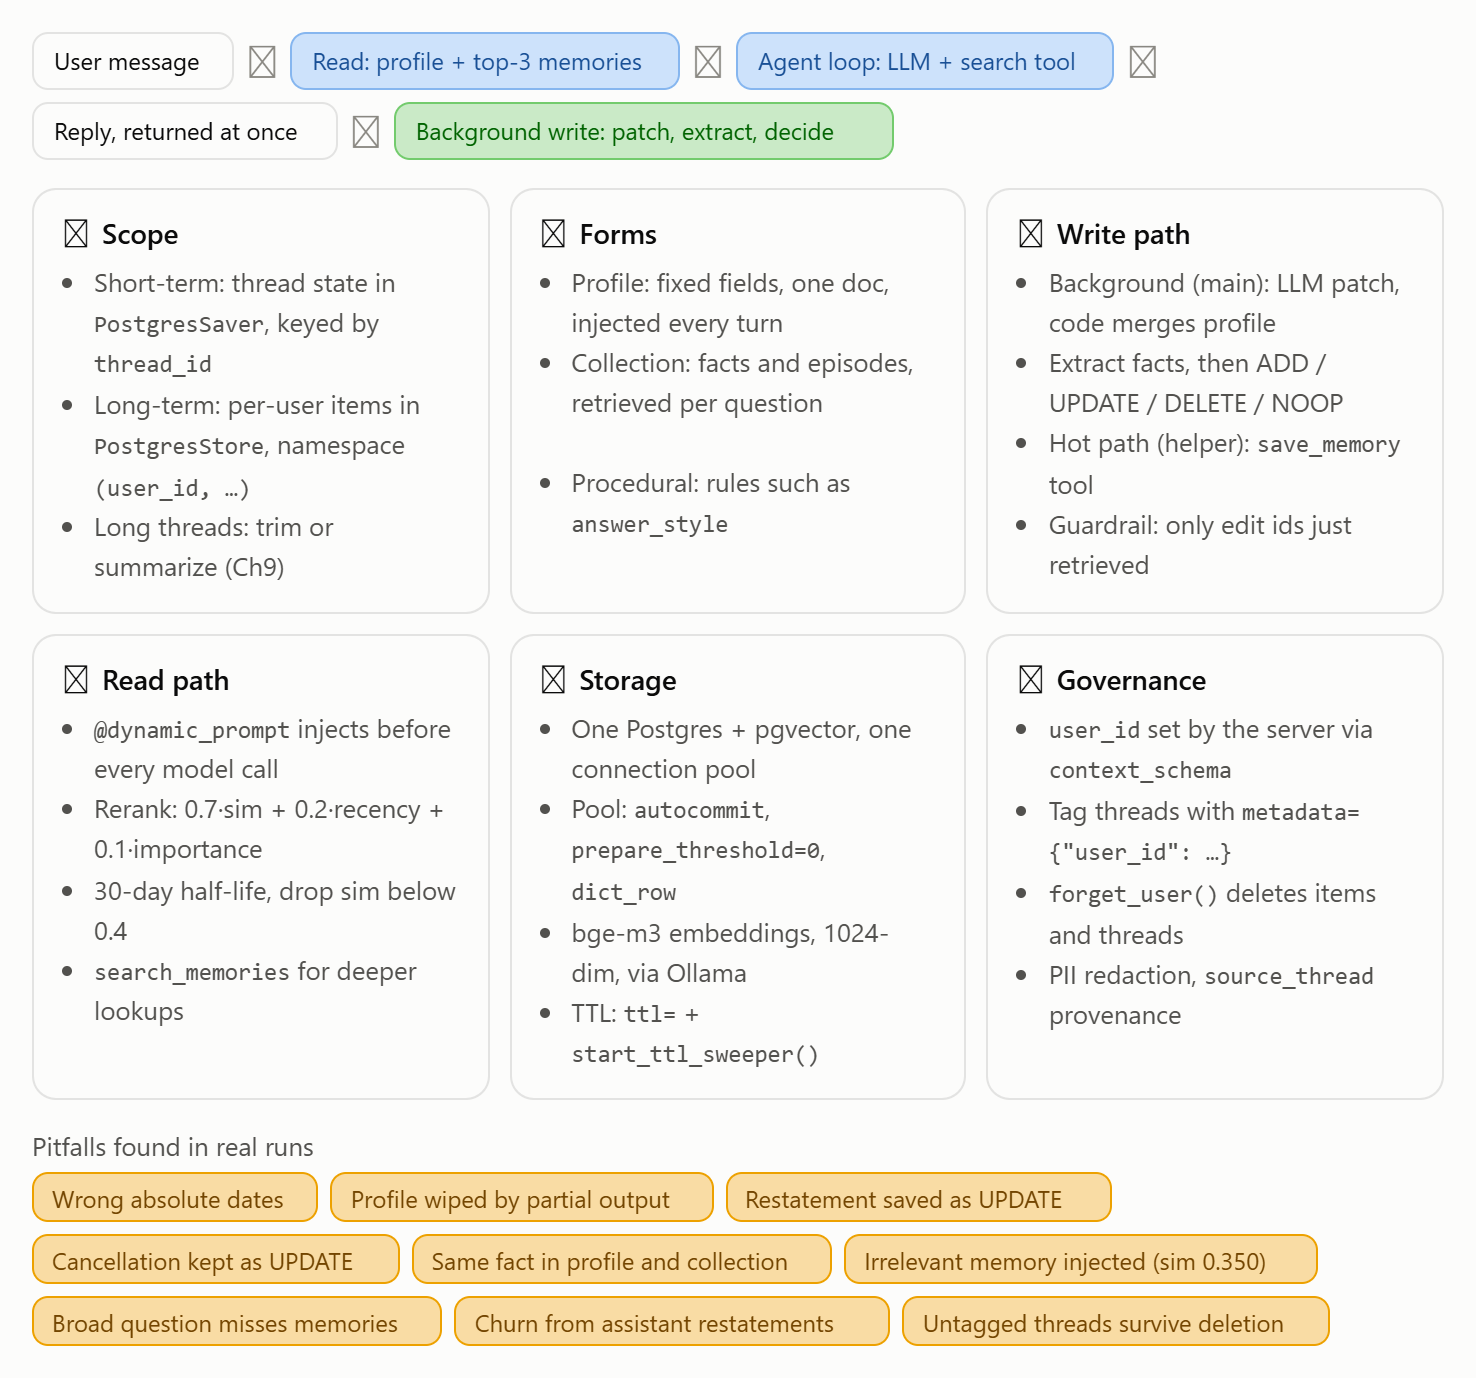


## Core idea
LLMs are stateless. "Memory" means deciding what goes into the context on every turn,
where it comes from, and who writes it and when.

## Five design decisions
| Decision | Our answer | Code |
|---|---|---|
| Scope | Short-term: thread state keyed by `thread_id`. Long-term: per-user items in namespaces `(user_id, ...)` | `PostgresSaver`, `PostgresStore` |
| Form | Profile: fixed fields, injected every turn. Collection: facts and episodes, retrieved per question. Procedural: rules such as `answer_style` | `UserProfile`, `(user_id, "memories")` |
| Who writes | Background extraction first; a hot-path tool as a helper | `remember()`, `save_memory` |
| How to read | Pre-fetch and inject first; tool search as a helper | `memory_prompt` (`@dynamic_prompt`), `search_memories` |
| Where to store | One Postgres + pgvector behind one connection pool | `PostgresSaver(pool)`, `PostgresStore(pool, index=...)` |

## Four core mechanisms
1. **Profile patches.** The LLM returns only the fields that changed (None means "unchanged"),
   and code merges them with `model_copy(update=...)`. Fields the model forgets are never wiped.
2. **Collection upkeep with ADD / UPDATE / DELETE / NOOP** (the mem0 pipeline).
   Extract candidate facts, retrieve similar existing memories, then let the LLM pick one action.
   Guardrail: `target_id in known`, so the model can only change memories it was just shown.
3. **Reranking on read.** `0.7 * similarity + 0.2 * recency + 0.1 * importance`,
   with recency halving every 30 days and matches below 0.4 similarity dropped.
4. **User isolation.** `user_id` is injected by the server through `context_schema`;
   the model can't see or change it. Threads carry `metadata={"user_id": ...}`,
   so "forget me" can find and delete them.

## Pitfalls found in real runs
| Pitfall | Symptom | Fix |
|---|---|---|
| Wrong dates | "Yesterday" stored as a wrong absolute date | Put today's date in the prompt |
| Profile wiped | A partial LLM output erased name and languages | LLM returns a patch; code merges |
| Restatement saved as UPDATE | A repeated fact rewrote a memory with a worse date | NOOP rule covers restatements |
| Cancellation kept | A cancelled trip became UPDATE, not DELETE | Explicit DELETE rule for contradictions and cancellations |
| Duplicates | The job landed in both the profile and the collection | Pass the current profile to the extractor |
| Irrelevant injection | A list-reversal answer congratulated the user on a project (sim 0.350) | Raise the threshold to 0.4; "never bring memories up unprompted" |
| Missed recall | After that fix, "What do you know about me?" missed the project (sim 0.359) | Calibrate thresholds on an eval set |
| Memory churn | The extractor re-read the assistant's restatement and made a useless UPDATE | Extract from user messages only (homework 2) |
| Privacy leak | Threads without a `user_id` tag survived deletion | Tag every thread from day one |

## Gaps before production
- Replace the thread pool with a real job queue (Celery / RQ / Arq / Kafka), with debouncing, retries and idempotency.
- Run memory jobs serially per user, or use optimistic locking, to avoid lost profile updates.
- Use a cheaper model for extraction, or batch several turns per job.
- Calibrate thresholds and rules on a memory eval set (LongMemEval / LoCoMo style).
- Trace which memories were injected and which operations ran (LangSmith / Langfuse).

## Interview talking points
1. **Short-term vs long-term:** split by scope. Thread state lives in the checkpointer; user-level data lives in a store or vector DB.
2. **Profile vs collection:** fixed fields go in the profile (always injected); open-ended facts go in the collection (retrieved, then reranked).
3. **Who writes and when:** background extraction first, hot path as a helper. Explain ADD/UPDATE/DELETE/NOOP and the "only retrieved ids" guardrail.
4. **How to read:** injection plus tool search; similarity x recency x importance scoring; thresholds must be calibrated (the 0.350 example).
5. **Pitfalls:** wrong dates, wiped profiles, duplicates, kept cancellations, irrelevant injection, churn, untagged threads.
6. **Privacy:** server-side namespaces, PII redaction before storage, provenance, one-click deletion, TTL for episodic memories.

**30-second answer:** "I split memory by scope. Short-term memory is the thread state, persisted by a checkpointer and trimmed or summarized when it grows. Long-term memory is per-user and lives in a vector-indexed store, namespaced by user_id, which the server sets. It has a small profile that is injected every turn and a collection that is retrieved per question and reranked by similarity, recency and importance. Writes happen mainly in a background job. It patches the profile, then extracts facts and compares each one with similar existing memories. An LLM decides add, update, delete or no-op, and it may only touch ids it was shown. Everything sits in one Postgres with pgvector and supports per-user deletion."

## Next: Agent + RAG (Chapter 8, Part 2)
Memory answers "who is this user and what happened"; RAG answers "what do the documents say".
Both are context sources that share one token budget.

| Pattern | How it works | Best for | Downside |
|---|---|---|---|
| Two-step RAG | Always retrieve, then generate | Q&A bots where every question needs documents | Retrieves for small talk too; can't do multi-hop |
| Agentic RAG | The retriever is a tool; the agent decides when, what and how often to search | Mixed tasks, multi-step questions | The agent may skip searching or write poor queries |
| Corrective / Self-RAG | A LangGraph flow: retrieve, grade, rewrite and retry, generate, check grounding | High-stakes domains such as medical or legal | More calls, higher latency |

Planned content:
- Offline ingestion: load, parse, chunk, embed, index.
- Online retrieval: query rewriting (multi-query, HyDE), BM25 + vector hybrid search, reranking, cited answers.
- Agent + RAG: a retriever-tool agent, a Corrective RAG graph, then `memory_prompt` plugged in for an agent with both user memory and a knowledge base.
- Evaluation: Recall@K and faithfulness.
- Project: a document Q&A assistant.